# Laboratory 9 — Comparing Multiple Models, Properly

**CN240 Data Science for Signal Processing · SF251 Introduction to Data Science**
Week 9 · Semester 1, Academic Year 2026 · Dr Surasak Phetmanee

---

| | |
|---|---|
| **Name** | *Ruth Benedicta Susanto* |
| **Student ID** | *6710755239* |
| **Section** | *750001* |

## What you will do today

Last week's number was *0.815 on one block split*. Today it grows up: **which** mistakes (precision, recall, F1),
**at what threshold** (the dial, ROC/AUC), **how lucky** (cross-validation, mean ± std), and **without cheating**
(tuning inside the folds, test set touched once). All of it on the **hard day** recording from Lab 8, where the
numbers are honest enough to have error bars.

**Deliverables (due before week 10, pushed to your GitHub repository):**
1. **The metric evidence** — hand-computed P/R/F1 for one class matching `classification_report` + the threshold you chose with its cost argument + the ROC figure
2. **The honest comparison** — one table: every model × (random folds, forward-in-time folds) as mean ± std with the per-fold scores, winner named or "no winner" defended
3. **Project evaluation table** — slide-14 items 1–4 on your project data (the draft of the week-12 milestone)

> **House rule (from today's lecture):** a difference smaller than the error bar is not a difference.


## Setup — run first, do not edit

Loads (or rebuilds) `har_features.csv`, rebuilds the **hard day** recording exactly as in Lab 8, and defines the
two splits. Nothing to edit here.


In [11]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import (train_test_split, cross_val_score, StratifiedKFold,
                                     GroupKFold, GridSearchCV)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             precision_score, recall_score, f1_score, roc_curve, roc_auc_score)

plt.rcParams['figure.figsize'] = (12, 4)
plt.rcParams['axes.grid'] = True
print("scikit-learn ready")

scikit-learn ready


In [2]:
# --- Load har_features.csv, or rebuild it with the reference pipeline ---------
try:
    har = pd.read_csv("har_features.csv")
    SRC = "your Lab 6 file"
except Exception:
    from scipy.signal import find_peaks
    FS, DUR = 50, 60
    def _synth(activity, rng):
        t = np.arange(0, DUR, 1 / FS); n = t.size
        if activity == "still":
            return pd.DataFrame({"ax_g": 0.02*rng.standard_normal(n),
                                 "ay_g": 0.02*rng.standard_normal(n),
                                 "az_g": 1 + 0.03*rng.standard_normal(n)})
        if activity == "walking":
            sw = np.sin(2*np.pi*0.9*t)
            return pd.DataFrame({"ax_g": 0.5*sw + 0.2*rng.standard_normal(n),
                                 "ay_g": 0.35*sw + 0.2*rng.standard_normal(n),
                                 "az_g": 1 + 0.3*np.abs(np.sin(np.pi*1.8*t))**8
                                          + 0.05*rng.standard_normal(n)})
        sw = np.sin(2*np.pi*1.3*t)
        return pd.DataFrame({"ax_g": 0.9*sw + 0.3*rng.standard_normal(n),
                             "ay_g": 0.6*sw + 0.3*rng.standard_normal(n),
                             "az_g": 1 + 0.8*np.abs(np.sin(np.pi*2.6*t))**6
                                      + 0.1*rng.standard_normal(n)})
    def _windows(x): return [x[s:s+100] for s in range(0, len(x)-100+1, 50)]
    def _spec(x):
        x = np.asarray(x, float); x = x - x.mean(); x = x * np.hanning(len(x))
        return np.fft.rfftfreq(len(x), 1/FS), np.abs(np.fft.rfft(x))/len(x)
    def _feats(w):
        w = np.asarray(w, float); d = w - w.mean()
        pk, _ = find_peaks(d, prominence=d.std(), distance=FS//4)
        f, mag = _spec(w); p = mag**2; p = p/(p.sum()+1e-12)
        band = (f >= 0.5) & (f <= 3.0)
        return {"mean": w.mean(), "std": w.std(), "rng": w.max()-w.min(),
                "zcr": np.sum(np.diff(np.sign(d)) != 0)/2.0,
                "peak_rate": len(pk)/2.0,
                "domfreq": f[mag[1:].argmax()+1], "bandE": p[band].sum(),
                "centroid": np.sum(f*p), "entropy": -np.sum(p*np.log2(p+1e-12))}
    rows = []
    for act in ("still", "walking", "running"):
        df = _synth(act, np.random.default_rng(240))
        ws = {a: _windows(df[a].values) for a in df.columns}
        for i in range(len(ws["az_g"])):
            rows.append({f"{a[:2]}_{k}": v for a in df.columns
                         for k, v in _feats(ws[a][i]).items()} | {"label": act})
    har = pd.DataFrame(rows)
    har.to_csv("har_features.csv", index=False)
    SRC = "rebuilt (reference pipeline)"

X = har.drop(columns="label")
y = har["label"]
print(f"matrix from {SRC}: {X.shape[0]} rows x {X.shape[1]} features · labels: {sorted(y.unique())}")

matrix from rebuilt (reference pipeline): 177 rows x 27 features · labels: ['running', 'still', 'walking']


In [3]:
from scipy.signal import find_peaks
FS, DUR = 50, 60

def synth_hard(activity, rng, noise=0.45, d=0.35):
    """a harder day: pace and swing DRIFT across the minute"""
    t = np.arange(0, DUR, 1 / FS); n = t.size; u = t / DUR
    N = lambda: noise * rng.standard_normal(n)
    if activity == "still":
        wob = 0.05 + d * 0.4 * u
        return pd.DataFrame({"ax_g": wob*np.sin(2*np.pi*0.4*t) + N(),
                             "ay_g": wob*np.cos(2*np.pi*0.3*t) + N(),
                             "az_g": 1 + d*0.1*u + N()})
    if activity == "walking":
        f = 0.9 + d*1.0*u;  a = 0.45 + d*1.0*u;  ph = 2*np.pi*np.cumsum(f)/FS
        return pd.DataFrame({"ax_g": a*np.sin(ph) + N(), "ay_g": 0.7*a*np.sin(ph) + N(),
                             "az_g": 1 + (0.25 + d*0.8*u)*np.abs(np.sin(ph))**6 + N()})
    f = 1.5 - d*0.8*u;  a = 1.0 - d*0.9*u;  ph = 2*np.pi*np.cumsum(f)/FS
    return pd.DataFrame({"ax_g": a*np.sin(ph) + N(), "ay_g": 0.7*a*np.sin(ph) + N(),
                         "az_g": 1 + (0.8 - d*0.9*u)*np.abs(np.sin(ph))**5 + N()})

def _windows(x): return [x[s:s+100] for s in range(0, len(x)-100+1, 50)]
def _spec(x):
    x = np.asarray(x, float); x = x - x.mean(); x = x * np.hanning(len(x))
    return np.fft.rfftfreq(len(x), 1/FS), np.abs(np.fft.rfft(x))/len(x)
def _feats(w):
    w = np.asarray(w, float); d = w - w.mean()
    pk, _ = find_peaks(d, prominence=d.std(), distance=FS//4)
    f, mag = _spec(w); p = mag**2; p = p/(p.sum()+1e-12); band = (f >= 0.5) & (f <= 3.0)
    return {"mean": w.mean(), "std": w.std(), "rng": w.max()-w.min(),
            "zcr": np.sum(np.diff(np.sign(d)) != 0)/2.0, "peak_rate": len(pk)/2.0,
            "domfreq": f[mag[1:].argmax()+1], "bandE": p[band].sum(),
            "centroid": np.sum(f*p), "entropy": -np.sum(p*np.log2(p+1e-12))}

rows = []
for act in ("still", "walking", "running"):
    df = synth_hard(act, np.random.default_rng(241))
    ws = {a: _windows(df[a].values) for a in df.columns}
    for i in range(len(ws["az_g"])):
        rows.append({f"{a[:2]}_{k}": v for a in df.columns for k, v in _feats(ws[a][i]).items()} | {"label": act})
hard = pd.DataFrame(rows)
Xh, yh = hard.drop(columns="label"), hard["label"]
print(f"hard day: {Xh.shape[0]} windows x {Xh.shape[1]} features — same recipe, drifting subject")

hard day: 177 windows x 27 features — same recipe, drifting subject


In [4]:
def block_split(df, frac=0.7):
    """time-ordered split within each label: (train_index, test_index)"""
    tr, te = [], []
    for label, g in df.groupby("label", sort=False):
        n = int(frac * len(g))
        tr += list(g.index[:n]);  te += list(g.index[n:])
    return tr, te

# time-block GROUPS for cross-validation: 4 consecutive blocks per label
def time_groups(df, n_blocks=4):
    g = pd.Series(0, index=df.index, dtype=int)
    for label, grp in df.groupby("label", sort=False):
        g.loc[grp.index] = np.arange(len(grp)) * n_blocks // len(grp)
    return g.values

TRh, TEh = block_split(hard)
GROUPS = time_groups(hard)

def forward_folds(groups):
    """forward-chaining time folds: train on blocks < k, test on block k -- the future is the only NEW data"""
    g = np.asarray(groups); idx = np.arange(len(g))
    return [(idx[g < k], idx[g == k]) for k in range(1, g.max() + 1)]
MODELS = {
    "dummy":   DummyClassifier(strategy="most_frequent"),
    "kNN k=5": make_pipeline(StandardScaler(), KNeighborsClassifier(5)),
    "tree":    DecisionTreeClassifier(random_state=0),
    "forest":  RandomForestClassifier(n_estimators=100, random_state=0),
    "SVM rbf": make_pipeline(StandardScaler(), SVC(probability=True, random_state=0)),
}
print(f"hard day: block split {len(TRh)}/{len(TEh)} · time blocks per label: {sorted(set(GROUPS.tolist()))}")

hard day: block split 123/54 · time blocks per label: [0, 1, 2, 3]


---
## Mission 1 — Deliverable 1 (part a): read the matrix by hand

Fit the **forest** on the hard-day block split and draw its confusion matrix (given). Then, **by hand from the
matrix**, compute precision, recall and F1 for the class **`running`** — and only then let
`classification_report` confirm you.

**TODO:** read TP, FP, FN for `running` off the matrix (rows = truth, columns = prediction; class order is
printed), and compute the three numbers.

class order: ['running', 'still', 'walking']
[[10  0  8]
 [ 0 18  0]
 [ 2  0 16]]


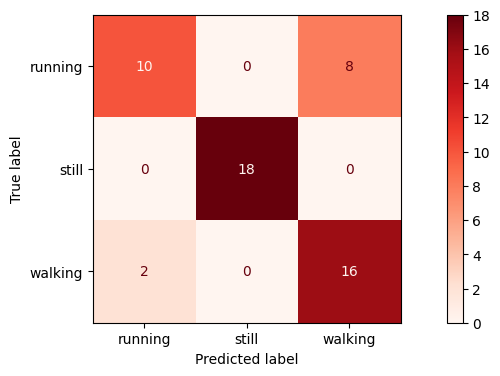

by hand — running: precision 0.833  recall 0.556  F1 0.667

classification_report says:
              precision    recall  f1-score   support

     running      0.833     0.556     0.667        18
       still      1.000     1.000     1.000        18
     walking      0.667     0.889     0.762        18

    accuracy                          0.815        54
   macro avg      0.833     0.815     0.810        54
weighted avg      0.833     0.815     0.810        54



In [5]:
forest = MODELS["forest"].fit(Xh.loc[TRh], yh.loc[TRh])
y_hat = forest.predict(Xh.loc[TEh])
labels = sorted(yh.unique())
cm = confusion_matrix(yh.loc[TEh], y_hat, labels=labels)
print("class order:", labels)
print(cm)
ConfusionMatrixDisplay(cm, display_labels=labels).plot(cmap="Reds"); plt.grid(False); plt.show()

# --- by hand, for 'running' -------------------------------------------------
TP = 10        # TODO: running rows predicted running
FP = 2         # TODO: NOT-running rows predicted running (column 'running', off-diagonal)
FN = 8         # TODO: running rows predicted something else (row 'running', off-diagonal)

if None in (TP, FP, FN):
    print("TODO: read TP, FP, FN for 'running' off the matrix")
else:
    P, R = TP / (TP + FP), TP / (TP + FN)
    F1 = 2 * P * R / (P + R)
    print(f"by hand — running: precision {P:.3f}  recall {R:.3f}  F1 {F1:.3f}")
    print("\nclassification_report says:")
    print(classification_report(yh.loc[TEh], y_hat, digits=3))

**Q1.** Which pair of classes carries the whole error? For `running`, which is higher — precision or
recall — and in one sentence what that means (does the model *miss* runners, or *over-call* them)?

Pair of running-walking. For running, precision is higher than recall, which means the model misses runners.

---
## Mission 2 — Deliverable 1 (part b): turn the dial

Make it a **binary** task — `running` (positive) vs not — and use the forest's `predict_proba`. Sweep the
threshold from 0.1 to 0.9 and record precision and recall at each. The plotting is given.

**TODO:** in the loop, turn `p` into predictions at threshold `t` and compute precision and recall for the
positive class. Then choose a threshold and defend it in Q2 with a *cost* argument.

,precision,recall
threshold,,
0.1,0.486,0.944
0.2,0.500,0.778
0.3,0.417,0.556
0.4,0.429,0.500
0.5,0.400,0.333
0.6,0.500,0.167
0.7,0.750,0.167
0.8,1.000,0.056
0.9,0.000,0.000


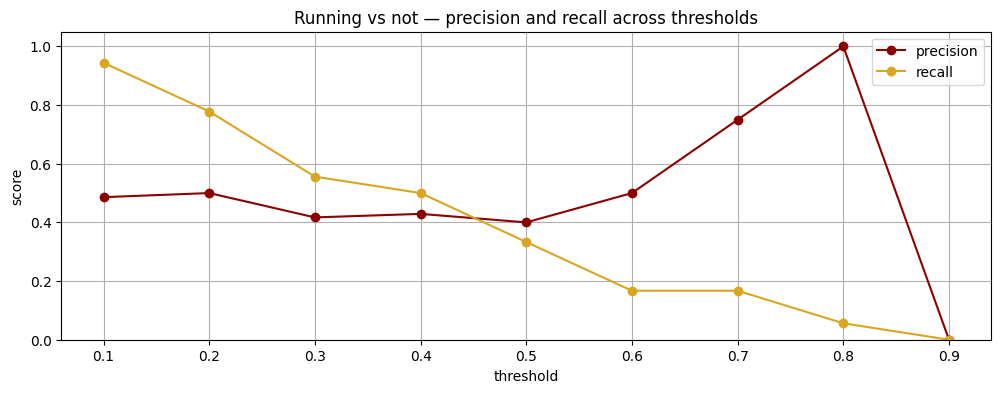

In [12]:
y_bin_tr = (yh.loc[TRh] == "running").astype(int)
y_bin_te = (yh.loc[TEh] == "running").astype(int)
forest_bin = RandomForestClassifier(n_estimators=100, random_state=0).fit(Xh.loc[TRh], y_bin_tr)
p = forest_bin.predict_proba(Xh.loc[TEh])[:, 1]  # P(running) for every test window

ts = np.round(np.arange(0.1, 0.91, 0.1), 1)
sweep = []
for t in ts:
    y_t = (p >= t).astype(int)
    sweep.append({"threshold": t,
                  "precision": precision_score(y_bin_te, y_t, zero_division=0),
                  "recall": recall_score(y_bin_te, y_t, zero_division=0)})

sw = pd.DataFrame(sweep).set_index("threshold").round(3)
display(sw)
sw.plot(marker="o", color=["darkred", "goldenrod"])
plt.ylim(0, 1.05)
plt.title("Running vs not — precision and recall across thresholds")
plt.ylabel("score")
plt.show()


**Q2.** Pick a threshold for a *fall-detection-style* alarm (a miss is expensive) and one for a
*spam-filter-style* decision (a false alarm is expensive). Give both numbers and one sentence each.

- Fall-detection-style: 0.1. Recall is 0.944, so this low threshold catches most positive running windows; precision is only 0.486, meaning more false alarms.
- Spam-filter-style: 0.8. Precision is 1.000 on this test block, so predicted positives are reliable; however, recall is only 0.056, so many true positives are missed.
These are illustrative operating points for the stated costs, not universal thresholds; choose them using the application's acceptable false-negative/false-positive trade-off.

---
## Mission 3 — Deliverable 1 (part c): the ROC curve, kNN vs forest

Every threshold at once. For the same binary task, draw the ROC of a **scaled kNN** and the **forest** on one
axis, AUC in the legend. `roc_curve` and `roc_auc_score` do the work — you wire them.

**TODO:** compute `fpr, tpr` for each model and its AUC.

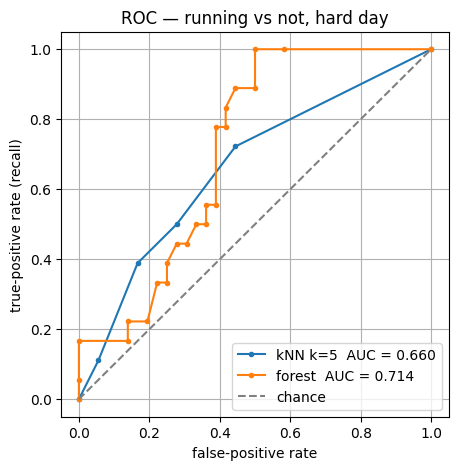

AUC comparison: {'kNN k=5': np.float64(0.66), 'forest': np.float64(0.714)}


In [13]:
knn_bin = make_pipeline(StandardScaler(), KNeighborsClassifier(5)).fit(Xh.loc[TRh], y_bin_tr)
curves = {}
for name, m in {"kNN k=5": knn_bin, "forest": forest_bin}.items():
    pm = m.predict_proba(Xh.loc[TEh])[:, 1]
    fpr, tpr, _ = roc_curve(y_bin_te, pm)
    auc = roc_auc_score(y_bin_te, pm)
    curves[name] = (fpr, tpr, auc)

plt.figure(figsize=(5, 5))
for name, (fpr, tpr, auc) in curves.items():
    plt.plot(fpr, tpr, marker=".", label=f"{name}  AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], "--", color="grey", label="chance")
plt.xlabel("false-positive rate")
plt.ylabel("true-positive rate (recall)")
plt.title("ROC — running vs not, hard day")
plt.legend()
plt.show()
print("AUC comparison:", {name: round(v[2], 3) for name, v in curves.items()})


**Q3.** Which model has the higher AUC — and is AUC the number you would use to choose the *shipping
threshold*? (One sentence: what is AUC for, what is the threshold for.)

The random forest has the higher AUC (0.714) than scaled kNN (0.660) on this held-out block. AUC measures ranking/discrimination across all thresholds, while the shipping threshold must be chosen separately to reflect the cost of false positives versus false negatives.

---
## Mission 4 — Deliverable 2: cross-validate twice, honestly

One split is one coin toss. Score every model with **5-fold StratifiedKFold** (random folds) and with
**forward-chaining time folds** (`forward_folds`: train on blocks 0..k−1, test on block k — the future is the
only thing that is genuinely *new*). Report **mean ± std** — and keep the per-fold scores, because on drifting
data the *last* fold is the one a deployed model would actually see.

`cross_val_score` accepts either a splitter object or a **list of (train, test) index pairs**, which is what
`forward_folds(GROUPS)` returns. (When your project has real groups — patients, machines — use `GroupKFold`;
when it has time, use forward folds like these or `TimeSeriesSplit`.)

**TODO:** build `cv_random = StratifiedKFold(5, shuffle=True, random_state=0)` and `cv_time = forward_folds(GROUPS)`.

In [14]:
cv_random = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
cv_time = forward_folds(GROUPS)

def cv_table(models, X, y, cv):
    rows = []
    for name, m in models.items():
        s = cross_val_score(m, X, y, cv=cv, scoring="accuracy")
        rows.append({"model": name, "mean ± std": f"{s.mean():.3f} ± {s.std():.3f}",
                     "per fold": " ".join(f"{v:.2f}" for v in s)})
    return pd.DataFrame(rows).set_index("model")

r = cv_table(MODELS, Xh, yh, cv_random)
t = cv_table(MODELS, Xh, yh, cv_time)
comparison = pd.concat({"random 5-fold": r, "forward time folds": t}, axis=1)
display(comparison)


random 5-fold                           forward time folds  \
            mean ± std                  per fold         mean ± std   
model                                                                 
dummy    0.322 ± 0.009  0.33 0.33 0.31 0.31 0.31      0.333 ± 0.000   
kNN k=5  0.853 ± 0.040  0.89 0.78 0.89 0.86 0.86      0.828 ± 0.165   
tree     0.876 ± 0.045  0.81 0.89 0.94 0.89 0.86      0.869 ± 0.080   
forest   0.915 ± 0.031  0.89 0.92 0.97 0.91 0.89      0.906 ± 0.103   
SVM rbf  0.848 ± 0.068  0.86 0.81 0.97 0.77 0.83      0.851 ± 0.152   

                         
               per fold  
model                    
dummy    0.33 0.33 0.33  
kNN k=5  0.96 0.93 0.60  
tree     0.89 0.96 0.76  
forest   1.00 0.96 0.76  
SVM rbf  1.00 0.91 0.64

**Checkpoint (reference run):** the two *means* are similar (≈ 0.85–0.92) — but the random-fold std is tiny
(≈ 0.03–0.07) while the forward-fold std is three to five times larger (≈ 0.10–0.17), because the per-fold scores
run something like `0.96 0.93 0.60`: the **last** fold — the furthest future — collapses. Same models, same data.

**Q4 (Deliverable 2).** (a) Why does the last forward fold score so much lower than the first two — what is
*new* about it that no random fold ever has to face? (b) Which single number would you quote to someone who will
deploy this next week: the random mean, the forward mean, or the last fold — and why? (c) On the forward column,
is there a winner whose gap over the runner-up beats the error bar? Name it, or write "no winner" and say which
model you would choose anyway and why.

(a) The last forward fold is the furthest-future time block. It contains the strongest later portion of the synthetic recording's changing pace and swing characteristics, i.e. temporal drift that random folds mix into both training and validation rather than testing as genuinely future data.

(b) I would quote the forward-fold mean as the average future-period estimate (forest: 0.906 ± 0.103) and also disclose the last-fold score (0.762) as a warning about the most recent period. The random-fold mean (0.915 ± 0.031) is optimistic for deployment because it does not preserve time order.

(c) No clear winner. The forest has the highest forward mean (0.906) versus the tree (0.869), but the gap (about 0.037) is smaller than the fold-to-fold variability (forest std about 0.103; tree std about 0.080). I would choose the forest provisionally because it has the best mean score, while reporting that its advantage is not decisive.

---
## Mission 5 — Tune inside the folds; touch the test set once

Last week's k-sweep was drawn on the test set — fine for *learning* what overfitting looks like, wrong for
*reporting*. Do it properly: `GridSearchCV` over k, with **forward time folds built from the training rows
only** (blocks 0–2; the last block *is* the test set), then score the winner on the test block exactly once.

**TODO:** build the search with `cv=forward_folds(np.asarray(GROUPS)[TRh])` and fit it on
`Xh.loc[TRh], yh.loc[TRh]`.

In [15]:
knn_pipe = make_pipeline(StandardScaler(), KNeighborsClassifier())
grid = {"kneighborsclassifier__n_neighbors": [1, 3, 5, 7, 9, 13, 17]}

# Inner forward folds are constructed using training rows only.
inner_folds = forward_folds(np.asarray(GROUPS)[TRh])
search = GridSearchCV(knn_pipe, grid, cv=inner_folds, scoring="accuracy", refit=True)
search.fit(Xh.loc[TRh], yh.loc[TRh])

res = pd.DataFrame(search.cv_results_)[
    ["param_kneighborsclassifier__n_neighbors", "mean_test_score", "std_test_score"]
]
res.columns = ["k", "validation mean", "validation std"]
display(res.round(3))
print("chosen without the test set:", search.best_params_)
print(f"test set, touched once: {search.score(Xh.loc[TEh], yh.loc[TEh]):.3f}")


,k,validation mean,validation std
0,1,0.959,0.019
1,3,0.959,0.019
2,5,0.963,0.007
3,7,0.947,0.008
4,9,0.947,0.008
5,13,0.914,0.025
6,17,0.925,0.014


chosen without the test set: {'kneighborsclassifier__n_neighbors': 5}
test set, touched once: 0.667


**Q5.** The validation folds promise about 0.95; the test block delivers about 0.65. Neither number is a bug.
In two sentences: what did the validation folds *not* contain that the test block does, and what should the
report say about the gap?

The inner forward-validation folds contain earlier time blocks (blocks 0–2) and do not include the final held-out block's later temporal drift. The selected k=5 achieves about 0.963 validation accuracy but 0.667 test accuracy; report the test result as the estimate on this unseen future block and explain the gap as evidence of temporal distribution shift, not as a reason to tune repeatedly on the test set.

---
## Mission 6 — Deliverable 3: the evaluation table for YOUR project

Upload `project.csv` (feature columns + `label`, rows in time order within each label — or with a `group`
column naming the patient / machine / day if you have one). Fill the four items of slide 14 that you can fill now:

1. **the split rule** — what is *new* data, and the fold scheme that respects it (a comment in the cell);
2. **the baseline** — dummy in the same table;
3. **the metric with its reason** — replace `scoring="accuracy"` with `"f1_macro"` (or `"recall_macro"`) and say why;
4. **mean ± std on honest folds** — `GroupKFold` on your groups if you have them (patients, machines, days),
   forward time folds otherwise.

In [10]:
import os
if os.path.exists("project.csv"):
    proj = pd.read_csv("project.csv")
    has_groups = "group" in proj.columns
    Xp = proj.drop(columns=[c for c in ("label", "group") if c in proj.columns])
    yp = proj["label"]
    gp = proj["group"].values if has_groups else time_groups(proj)
    # TODO (milestone draft): your split rule, as a comment: what is NEW data, and why these folds respect it
    SCORING = "accuracy"     # TODO: "f1_macro" or "recall_macro" — and say why in the report
    rows = []
    for name, m in MODELS.items():
        if has_groups:
            s = cross_val_score(m, Xp, yp, cv=GroupKFold(n_splits=min(4, len(set(gp)))), groups=gp, scoring=SCORING)
        else:
            s = cross_val_score(m, Xp, yp, cv=forward_folds(gp), scoring=SCORING)
        rows.append({"model": name, SCORING: f"{s.mean():.3f} ± {s.std():.3f}", "per fold": " ".join(f"{v:.2f}" for v in s)})
    print(f"project: {Xp.shape[0]} rows x {Xp.shape[1]} features · groups: {len(set(gp))} ({'given' if has_groups else 'time blocks'})")
    display(pd.DataFrame(rows).set_index("model"))
else:
    print("project.csv not found — upload it via the Files pane (Deliverable 3)")

project.csv not found — upload it via the Files pane (Deliverable 3)


**Project evaluation table (Deliverable 3)** — four lines below: the split rule, the metric and its cost reason,
the baseline vs the best model as mean ± std, and whether the winner's gap beats its error bar.

*(your report)*

---
## Before you submit (checklist)

- [ ] Whole notebook runs top to bottom — **Runtime → Restart and run all must pass**
- [ ] Mission 1: hand-computed P/R/F1 for `running` matches the report + Q1
- [ ] Mission 2: threshold table + figure + Q2 (two thresholds, two cost arguments)
- [ ] Mission 3: ROC figure with AUCs + Q3 (Deliverable 1 complete)
- [ ] Mission 4: the random-vs-forward comparison table with per-fold scores + Q4 (Deliverable 2)
- [ ] Mission 5: GridSearchCV table on forward folds, chosen k, test touched once + Q5
- [ ] Mission 6: project table + four-line evaluation report (Deliverable 3)
- [ ] Pushed to your GitHub repository

*Next week: **Deep Learning** — a network that learns its own features from the raw ECG; the "improved model"
milestone is evaluated with today's protocol or it does not count.*
